C:\Users\Пользователь\AppData\Local\Temp\ipykernel_25648\3106092045.py:17: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  purchases['order_week'] = purchases['event_time'].dt.to_period('W').dt.start_time


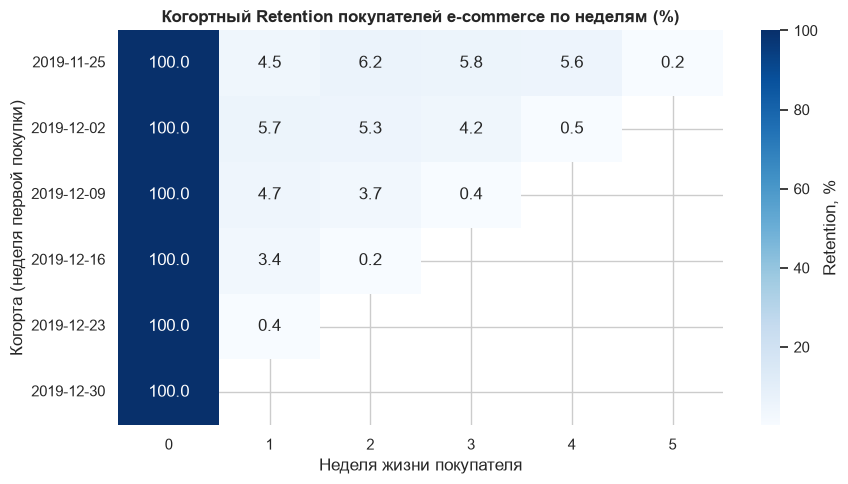

--- КОГОРТНЫЙ RETENTION (%) ---
week_num         0     1     2     3     4     5
cohort_week                                     
2019-11-25   100.0  4.48  6.18  5.82  5.58  0.24
2019-12-02   100.0  5.73  5.33  4.25  0.54   NaN
2019-12-09   100.0  4.69  3.69  0.39   NaN   NaN
2019-12-16   100.0  3.39  0.20   NaN   NaN   NaN
2019-12-23   100.0  0.38   NaN   NaN   NaN   NaN
2019-12-30   100.0   NaN   NaN   NaN   NaN   NaN

--- ПРОВЕРКА ГИПОТЕЗЫ (AOV) ---
С брендом: медиана = $27.93, среднее = $39.01 (n=25240)
Без бренда: медиана = $18.33, среднее = $25.49 (n=3654)
Mann-Whitney U p-value = 0.000000


In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")

# 1. Загрузка и очистка
df = pd.read_csv('2019-Dec.csv')
df = df[df['price'] > 0].drop_duplicates()
df['event_time'] = pd.to_datetime(df['event_time'])
df['brand'] = df['brand'].fillna('no_brand')

# 2. Когортный Retention покупателей по неделям декабря
purchases = df[df['event_type'] == 'purchase'].copy()
purchases['order_week'] = purchases['event_time'].dt.to_period('W').dt.start_time
purchases['cohort_week'] = purchases.groupby('user_id')['order_week'].transform('min')
purchases['week_num'] = ((purchases['order_week'] - purchases['cohort_week']).dt.days // 7)

cohort_data = purchases.groupby(['cohort_week', 'week_num'])['user_id'].nunique().reset_index()
cohort_pivot = cohort_data.pivot(index='cohort_week', columns='week_num', values='user_id')
retention = cohort_pivot.divide(cohort_pivot.iloc[:, 0], axis=0) * 100
retention.index = retention.index.strftime('%Y-%m-%d')

plt.figure(figsize=(9, 5))
sns.heatmap(retention, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': 'Retention, %'})
plt.title('Когортный Retention покупателей e-commerce по неделям (%)', fontsize=12, fontweight='bold')
plt.ylabel('Когорта (неделя первой покупки)')
plt.xlabel('Неделя жизни покупателя')
plt.tight_layout()
plt.savefig('cohort_retention.png', dpi=150)
plt.show()

print("--- КОГОРТНЫЙ RETENTION (%) ---")
print(retention.round(2))

# 3. Проверка гипотезы: отличается ли средний чек (AOV) заказов с брендом от no_brand
session_orders = purchases.groupby('user_session').agg(
    order_sum=('price', 'sum'),
    has_brand=('brand', lambda x: (x != 'no_brand').any())
).reset_index()

brand_orders = session_orders[session_orders['has_brand']]['order_sum']
nobrand_orders = session_orders[~session_orders['has_brand']]['order_sum']

stat, p_val = stats.mannwhitneyu(brand_orders, nobrand_orders, alternative='two-sided')
print("\n--- ПРОВЕРКА ГИПОТЕЗЫ (AOV) ---")
print(f"С брендом: медиана = ${brand_orders.median():.2f}, среднее = ${brand_orders.mean():.2f} (n={len(brand_orders)})")
print(f"Без бренда: медиана = ${nobrand_orders.median():.2f}, среднее = ${nobrand_orders.mean():.2f} (n={len(nobrand_orders)})")
print(f"Mann-Whitney U p-value = {p_val:.6f}")
